<a href="https://colab.research.google.com/github/axelr004/AD_2026Q4_Grupo20/blob/main/ComparacionClimaticaCompletaGrupo20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#descripcion e introducion en : AE3/README.md

#Integramos las librerias

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", None)
print("Librerias cargadas correctamente")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

Librerias cargadas correctamente
Pandas: 2.2.3
NumPy: 2.4.6


#cargamos los CSV que subimos a gifhub
Los datos climáticos que usamos son de Medellín y Madrid durante el periodo de el 1 de enero y el 31 de diciembre de 2023. Se obtuvieron mediante la API histórica de Open-Meteo, utilizando el modelo ERA5.

In [ ]:
URL_MED = "https://raw.githubusercontent.com/axelr004/AD_2026Q4_Grupo20/main/AE3/datos/medellin.csv"
URL_MAD = "https://raw.githubusercontent.com/axelr004/AD_2026Q4_Grupo20/main/AE3/datos/madrid.csv"

medellin = pd.read_csv(URL_MED)
madrid = pd.read_csv(URL_MAD)

print("Datos de Medellin:")
display(medellin.head())
print("Datos de Madrid:")
display(madrid.head())

Datos de Medellin:


,fecha,temperatura_max_c,precipitacion_mm
0,2023-01-01,23.8,14.5
1,2023-01-02,26.2,7.9
2,2023-01-03,23.5,9.6
3,2023-01-04,25.1,9.0
4,2023-01-05,25.7,6.9


Datos de Madrid:


,fecha,temperatura_max_c,precipitacion_mm
0,2023-01-01,14.8,0.0
1,2023-01-02,12.3,1.0
2,2023-01-03,11.8,0.0
3,2023-01-04,12.3,0.0
4,2023-01-05,12.5,0.0


#Exploración de los datos con Pandas
Se revisaron las dimensiones, tipos de datos, valores estadísticos, registros duplicados y posibles valores faltantes, con el propósito de conocer la calidad de la información antes de seguir con el análisis.

In [ ]:
# DIMENSIONES DE LOS CONJUNTOS DE DATOS

print("MEDELLiN")
print("Filas y columnas:", medellin.shape)

print("\nMADRID")
print("Filas y columnas:", madrid.shape)

MEDELLiN
Filas y columnas: (365, 3)

MADRID
Filas y columnas: (365, 3)


Primeros registros

In [ ]:
# VISUALIZACION DE LOS PRIMEROS REGISTROS

print("Primeros registros de Medellin:")
display(medellin.head())

print("Primeros registros de Madrid:")
display(madrid.head())

Primeros registros de Medellin:


,fecha,temperatura_max_c,precipitacion_mm
0,2023-01-01,23.8,14.5
1,2023-01-02,26.2,7.9
2,2023-01-03,23.5,9.6
3,2023-01-04,25.1,9.0
4,2023-01-05,25.7,6.9


Primeros registros de Madrid:


,fecha,temperatura_max_c,precipitacion_mm
0,2023-01-01,14.8,0.0
1,2023-01-02,12.3,1.0
2,2023-01-03,11.8,0.0
3,2023-01-04,12.3,0.0
4,2023-01-05,12.5,0.0


Informacion y tipos de datos

In [ ]:
# INFORMACIÓN GENERAL

print("Información de Medellin:")
medellin.info()

print("\nInformación de Madrid:")
madrid.info()

Información de Medellin:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 3 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   fecha              365 non-null    object 
 1   temperatura_max_c  365 non-null    float64
 2   precipitacion_mm   365 non-null    float64
dtypes: float64(2), object(1)
memory usage: 8.7+ KB

Información de Madrid:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 3 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   fecha              365 non-null    object 
 1   temperatura_max_c  365 non-null    float64
 2   precipitacion_mm   365 non-null    float64
dtypes: float64(2), object(1)
memory usage: 8.7+ KB


Estadisticas descriptivas

In [ ]:
# ESTADISTICAS DESCRIPTIVAS

print("Estadísticas de Medellin:")
display(medellin.describe())

print("Estadísticas de Madrid:")
display(madrid.describe())

Estadísticas de Medellin:


,temperatura_max_c,precipitacion_mm
count,365.000000,365.000000
mean,27.533151,7.621918
std,2.098776,7.863940
min,21.300000,0.000000
25%,26.200000,1.600000
50%,27.500000,5.500000
75%,29.300000,11.500000
max,32.800000,74.900000


Estadísticas de Madrid:


,temperatura_max_c,precipitacion_mm
count,365.000000,365.000000
mean,21.887671,1.197808
std,8.807900,4.571056
min,5.900000,0.000000
25%,14.200000,0.000000
50%,21.500000,0.000000
75%,28.500000,0.200000
max,39.300000,49.800000


Valores faltantes y duplicados

In [ ]:
# REVISION DE VALORES FALTANTES

print("Valores faltantes en Medellin:")
display(medellin.isnull().sum())

print("Valores faltantes en Madrid:")
display(madrid.isnull().sum())

print("Registros duplicados en Medellin:", medellin.duplicated().sum())

print("Registros duplicados en Madrid:", madrid.duplicated().sum())

Valores faltantes en Medellin:


,0
fecha,0
temperatura_max_c,0
precipitacion_mm,0


Valores faltantes en Madrid:


,0
fecha,0
temperatura_max_c,0
precipitacion_mm,0


Registros duplicados en Medellin: 0
Registros duplicados en Madrid: 0


Limpieza y conversion de datos

In [ ]:
# LIMPIEZA Y CONVERSIoN DE TIPOS DE DATOS

medellin = medellin.copy()
madrid = madrid.copy()

# Convertir fechas
medellin["fecha"] = pd.to_datetime( medellin["fecha"], errors="coerce" )
madrid["fecha"] = pd.to_datetime( madrid["fecha"], errors="coerce" )

# Convertir variables climáticas a valores numéricos
columnas_numericas = [ "temperatura_max_c", "precipitacion_mm" ]

for columna in columnas_numericas:
 medellin[columna] = pd.to_numeric( medellin[columna], errors="coerce" )
 madrid[columna] = pd.to_numeric( madrid[columna], errors="coerce" )

# Eliminar duplicados exactos
medellin = medellin.drop_duplicates()
madrid = madrid.drop_duplicates()

print("Tipos de datos despues de la conversion:")
print("\nMedellin:")
print(medellin.dtypes)
print("\nMadrid:")
print(madrid.dtypes)

Tipos de datos despues de la conversion:

Medellin:
fecha                datetime64[ns]
temperatura_max_c           float64
precipitacion_mm            float64
dtype: object

Madrid:
fecha                datetime64[ns]
temperatura_max_c           float64
precipitacion_mm            float64
dtype: object


Comprobacion de la limpieza



In [ ]:
# COMPROBACION FINAL

print("Valores faltantes después de la conversión:")
print("\nMedellin:")
display(medellin.isnull().sum())

print("\nMadrid:")
display(madrid.isnull().sum())
print("Dimensiones finales:")
print("Medellin:", medellin.shape)
print("Madrid:", madrid.shape)

Valores faltantes después de la conversión:

Medellin:


,0
fecha,0
temperatura_max_c,0
precipitacion_mm,0



Madrid:


,0
fecha,0
temperatura_max_c,0
precipitacion_mm,0


Dimensiones finales:
Medellin: (365, 3)
Madrid: (365, 3)


#Integración de los conjuntos de datos
se integraron los registros climaticos de Medellín y Madrid mediante la columna fecha. Se utiliza una union interna (inner join) para conservar unicamente los dias que tienen informacion disponible en ambas ciudades

In [ ]:
# UNION DE LOS DATOS DE AMBAS CIUDADES

comparacion = pd.merge( medellin, madrid, on="fecha", how="inner", suffixes=("_med", "_mad"), validate="one_to_one" )

print("Cantidad de fechas comparables:", len(comparacion))
display(comparacion.head())

Cantidad de fechas comparables: 365


,fecha,temperatura_max_c_med,precipitacion_mm_med,temperatura_max_c_mad,precipitacion_mm_mad
0,2023-01-01,23.8,14.5,14.8,0.0
1,2023-01-02,26.2,7.9,12.3,1.0
2,2023-01-03,23.5,9.6,11.8,0.0
3,2023-01-04,25.1,9.0,12.3,0.0
4,2023-01-05,25.7,6.9,12.5,0.0


Verifiamos los datos integrados

In [ ]:
# VERIFICACIÓN DE LOS DATOS INTEGRADOS

columnas_comparacion = [ "temperatura_max_c_med", "precipitacion_mm_med", "temperatura_max_c_mad", "precipitacion_mm_mad" ]

print("Valores faltantes:")
display(comparacion[columnas_comparacion].isnull().sum())

print("Fechas duplicadas:", comparacion["fecha"].duplicated().sum())
print("Periodo analizado:")
print("Fecha inicial:", comparacion["fecha"].min())
print("Fecha final:", comparacion["fecha"].max())

Valores faltantes:


,0
temperatura_max_c_med,0
precipitacion_mm_med,0
temperatura_max_c_mad,0
precipitacion_mm_mad,0


Fechas duplicadas: 0
Periodo analizado:
Fecha inicial: 2023-01-01 00:00:00
Fecha final: 2023-12-31 00:00:00


tabla definitiva
excluimos unicamente los dias que no tengan informacion completa en alguna de las cuatro variables

In [ ]:
# PREPARACION DE TABLA DEFINITIVA

registros_iniciales = len(comparacion)
comparacion = comparacion.dropna( subset=columnas_comparacion ).copy()

registros_finales = len(comparacion)
print("Registros antes de filtrar:", registros_iniciales)
print("Registros después de filtrar:", registros_finales)
print("Registros excluidos:", registros_iniciales - registros_finales)
display(comparacion.head())

Registros antes de filtrar: 365
Registros después de filtrar: 365
Registros excluidos: 0


,fecha,temperatura_max_c_med,precipitacion_mm_med,temperatura_max_c_mad,precipitacion_mm_mad
0,2023-01-01,23.8,14.5,14.8,0.0
1,2023-01-02,26.2,7.9,12.3,1.0
2,2023-01-03,23.5,9.6,11.8,0.0
3,2023-01-04,25.1,9.0,12.3,0.0
4,2023-01-05,25.7,6.9,12.5,0.0


#Analisis de datos con NumPy
utilizamos biblioteca NumPy para transformar las variables climaticas en arreglos numéricos. Esto permite realizar operaciones matemáticas, seleccionar registros mediante condiciones lógicas y calcular estadísticas para comparar el comportamiento climático de Medellín y Madrid.


In [ ]:
# CONVERSION DE LOS DATOS A ARREGLOS NUMPY

fechas = comparacion["fecha"].to_numpy()

temp_med = comparacion[ "temperatura_max_c_med" ].to_numpy(dtype=float)
temp_mad = comparacion[ "temperatura_max_c_mad" ].to_numpy(dtype=float)
prec_med = comparacion[ "precipitacion_mm_med" ].to_numpy(dtype=float)
prec_mad = comparacion[ "precipitacion_mm_mad" ].to_numpy(dtype=float)

print("Cantidad de datos por variable:")
print("Temperatura Medellín:", len(temp_med))
print("Temperatura Madrid:", len(temp_mad))
print("Precipitación Medellín:", len(prec_med))
print("Precipitación Madrid:", len(prec_mad))

Cantidad de datos por variable:
Temperatura Medellín: 365
Temperatura Madrid: 365
Precipitación Medellín: 365
Precipitación Madrid: 365


Indexacion y slicing

In [ ]:
# INDEXACIÓN Y SLICING

print("Primera temperatura máxima de Medellin:")
print(temp_med[0])

print("\nPrimeros 10 registros de temperatura de Medellin:")
print(temp_med[:10])

print("\nRegistros del 11 al 20 de temperatura de Madrid:")
print(temp_mad[10:20])

Primera temperatura máxima de Medellin:
23.8

Primeros 10 registros de temperatura de Medellin:
[23.8 26.2 23.5 25.1 25.7 25.2 23.7 23.5 23.8 22.2]

Registros del 11 al 20 de temperatura de Madrid:
[10.6 10.5 11.  10.2  9.6 10.4 10.   6.6  8.3 13.5]


Mascaras booleanas
con esto identificamos días lluviosos y días con temperaturas máximas superiores a 25 °C

In [ ]:
# MASCARAS BOOLEANAS

lluvia_med = prec_med > 0.1
lluvia_mad = prec_mad > 0.1
calor_med = temp_med > 25
calor_mad = temp_mad > 25

print("Dias con precipitacion superior a 0.1 mm:")
print("Medellín:", np.count_nonzero(lluvia_med))
print("Madrid:", np.count_nonzero(lluvia_mad))
print("\nDías con temperatura máxima superior a 25 °C:")
print("Medellín:", np.count_nonzero(calor_med))
print("Madrid:", np.count_nonzero(calor_mad))

Dias con precipitacion superior a 0.1 mm:
Medellín: 342
Madrid: 99

Días con temperatura máxima superior a 25 °C:
Medellín: 319
Madrid: 136


broadcasting

In [ ]:
# BROADCASTING

matriz_temperaturas = np.column_stack( (temp_med, temp_mad) )

medias_temperaturas = np.mean( matriz_temperaturas, axis=0, keepdims=True )

temperaturas_centradas = ( matriz_temperaturas - medias_temperaturas )

print("Matriz de temperaturas:")
print(matriz_temperaturas[:5])

print("\nPromedios de temperatura:")
print(medias_temperaturas)

print("\nTemperaturas centradas:")
print(temperaturas_centradas[:5])

Matriz de temperaturas:
[[23.8 14.8]
 [26.2 12.3]
 [23.5 11.8]
 [25.1 12.3]
 [25.7 12.5]]

Promedios de temperatura:
[[27.53315068 21.88767123]]

Temperaturas centradas:
[[ -3.73315068  -7.08767123]
 [ -1.33315068  -9.58767123]
 [ -4.03315068 -10.08767123]
 [ -2.43315068  -9.58767123]
 [ -1.83315068  -9.38767123]]


#Estadisticas descriptivas
calculamos medidas para comparar las condiciones climáticas de Medellín y Madrid. Se utilizan funciones de NumPy para obtener promedios, valores mínimos, máximos, acumulados y cantidad de días con precipitación.


Estadistica de temperatura

In [ ]:
# ESTADISTICAS DE TEMPERATURA

print("TEMPERATURA MAXIMA - MEDELLIN")
print("Promedio:", round(np.mean(temp_med), 2), "°C")
print("Minima:", round(np.min(temp_med), 2), "°C")
print("Maxima:", round(np.max(temp_med), 2), "°C")
print("Desviación estándar:", round(np.std(temp_med), 2), "°C")

print("\nTEMPERATURA MAXIMA - MADRID")
print("Promedio:", round(np.mean(temp_mad), 2), "°C")
print("Minima:", round(np.min(temp_mad), 2), "°C")
print("Maxima:", round(np.max(temp_mad), 2), "°C")
print("Desviación estandar:", round(np.std(temp_mad), 2), "°C")

TEMPERATURA MAXIMA - MEDELLIN
Promedio: 27.53 °C
Minima: 21.3 °C
Maxima: 32.8 °C
Desviación estándar: 2.1 °C

TEMPERATURA MAXIMA - MADRID
Promedio: 21.89 °C
Minima: 5.9 °C
Maxima: 39.3 °C
Desviación estandar: 8.8 °C


precipitación

In [ ]:
# ESTADÍSTICAS DE PRECIPITACIÓN

print("PRECIPITACION - MEDELLIN")
print("Promedio diario:", round(np.mean(prec_med), 2), "mm")
print("Minima:", round(np.min(prec_med), 2), "mm")
print("Maxima:", round(np.max(prec_med), 2), "mm")
print("Acumulado:", round(np.sum(prec_med), 2), "mm")
print("Dias lluviosos:", np.count_nonzero(prec_med > 0.1))

print("\nPRECIPITACIÓN - MADRID")
print("Promedio diario:", round(np.mean(prec_mad), 2), "mm")
print("Minima:", round(np.min(prec_mad), 2), "mm")
print("Maxima:", round(np.max(prec_mad), 2), "mm")
print("Acumulado:", round(np.sum(prec_mad), 2), "mm")
print("Dias lluviosos:", np.count_nonzero(prec_mad > 0.1))

PRECIPITACION - MEDELLIN
Promedio diario: 7.62 mm
Minima: 0.0 mm
Maxima: 74.9 mm
Acumulado: 2782.0 mm
Dias lluviosos: 342

PRECIPITACIÓN - MADRID
Promedio diario: 1.2 mm
Minima: 0.0 mm
Maxima: 49.8 mm
Acumulado: 437.2 mm
Dias lluviosos: 99


#Visualizar y comparación grafica
Se utilizan graficos para representar el comportamiento de la temperatura maxima y la precipitación de Medellin y Madrid durante 2023

datos mensuales

In [ ]:
# AGRUPACIÓN DE DATOS POR MES

comparacion["mes"] = comparacion["fecha"].dt.month

mensual = comparacion.groupby("mes").agg({ "temperatura_max_c_med": "mean", "temperatura_max_c_mad": "mean", "precipitacion_mm_med": "sum", "precipitacion_mm_mad": "sum" })
nombres_meses = [ "Enero", "Febrero", "Marzo", "Abril", "Mayo", "Junio", "Julio", "Agosto", "Septiembre", "Octubre", "Noviembre", "Diciembre" ]

print("Resumen climatico mensual:")
display(mensual.round(2))

Resumen climatico mensual:


,temperatura_max_c_med,temperatura_max_c_mad,precipitacion_mm_med,precipitacion_mm_mad
mes,,,,
1,25.76,10.35,219.3,21.4
2,26.43,12.89,146.3,5.8
3,25.43,18.74,432.2,9.0
4,26.29,24.35,414.3,6.9
5,27.57,23.53,306.6,43.1
6,28.41,28.85,166.2,41.9
7,29.21,34.27,138.3,3.2
8,29.72,34.69,154.4,0.0
9,29.69,25.39,143.3,128.0


Grafico de temperatura maxima mensual

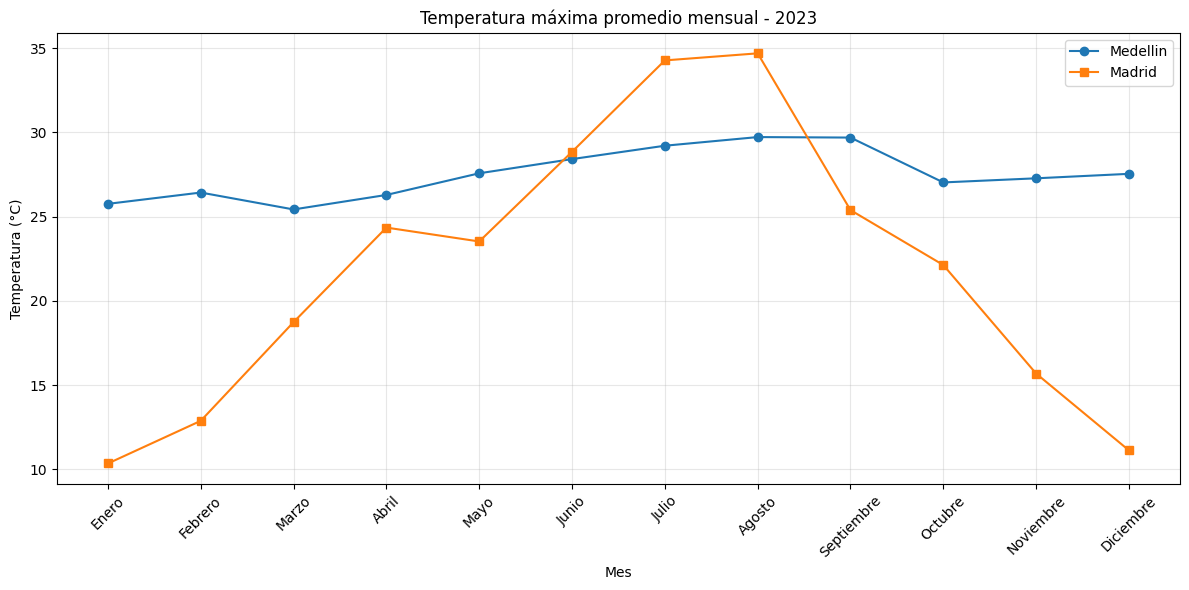

In [ ]:
# COMPARACIÓN DE TEMPERATURA MAXIMA MENSUAL

plt.figure(figsize=(12, 6))

plt.plot( mensual.index, mensual["temperatura_max_c_med"], marker="o", label="Medellin" )
plt.plot( mensual.index, mensual["temperatura_max_c_mad"], marker="s", label="Madrid" )

plt.title("Temperatura máxima promedio mensual - 2023")
plt.xlabel("Mes")
plt.ylabel("Temperatura (°C)")
plt.xticks(range(1, 13), nombres_meses, rotation=45)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

La gráfica nos permite observar diferencias importantes en el comportamiento de la temperatura máxima mensual ambas ciudades,
medellin presenta un comportamiento relativamente estable durante el año, con temperaturas máximas promedio mensuales entre 25,43 °C y 29,72 °C. Su valor más alto se registra en agosto.
Por otra parte, madrid presenta una variación termica ms marcada. Durante enero registra un promedio de 10,35 °C, mientras que en agosto alcanza aproximadamente 34,69 °C.
Estos resultados muestran que Madrid presenta mayores cambios de temperatura entre los meses del año, mientras que Medellin mantiene temperaturas maximas mas constantes.

------------------------------------------------------------------------------------------------------------------------------------------

Grafico de precipitacion mensual

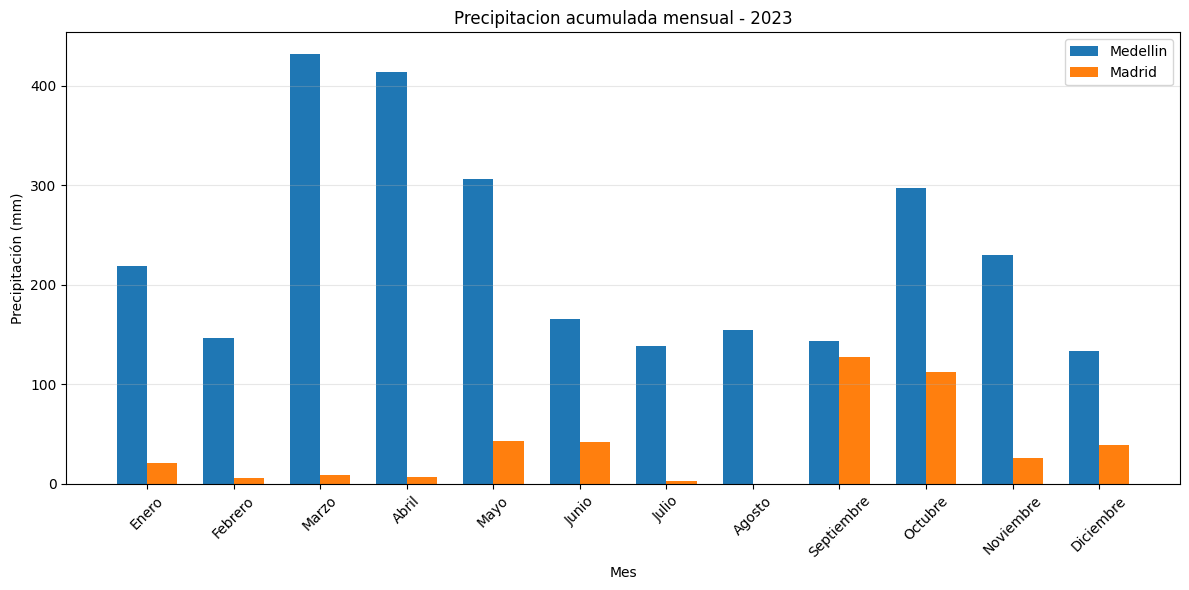

In [ ]:
# COMPARACIÓN DE PRECIPITACIÓN MENSUAL

posiciones = np.arange(len(mensual))
ancho = 0.35

plt.figure(figsize=(12, 6))

plt.bar( posiciones - ancho/2, mensual["precipitacion_mm_med"], ancho, label="Medellin" )
plt.bar( posiciones + ancho/2, mensual["precipitacion_mm_mad"], ancho, label="Madrid" )

plt.title("Precipitacion acumulada mensual - 2023")
plt.xlabel("Mes")
plt.ylabel("Precipitación (mm)")
plt.xticks(posiciones, nombres_meses, rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


esta grafica nos permitio identificar diferencias en la distribución de las lluvias entre ambas ciudades, medellín presenta mayores acumulaciones de precipitación durante el año. Su mes con mayor registro es marzo, con 432,2 mm, seguido de abril con 414,3 mm.
En Madrid, la mayor precipitación mensual se presenta en septiembre, con 128 mm, seguido de octubre con 112,8 mm. También se observa un periodo de menor precipitación durante los meses de verano, especialmente en agosto, cuando el registro fue de 0 mm.
En general, los datos muestran que medellin presenta una mayor acumulacion de precipitaciones durante el periodo analizado, mientras que Madrid tiene una distribución mensual mas variable

------------------------------------------------------------------------------------------------------------------------------------------

Histograma de temperaturas

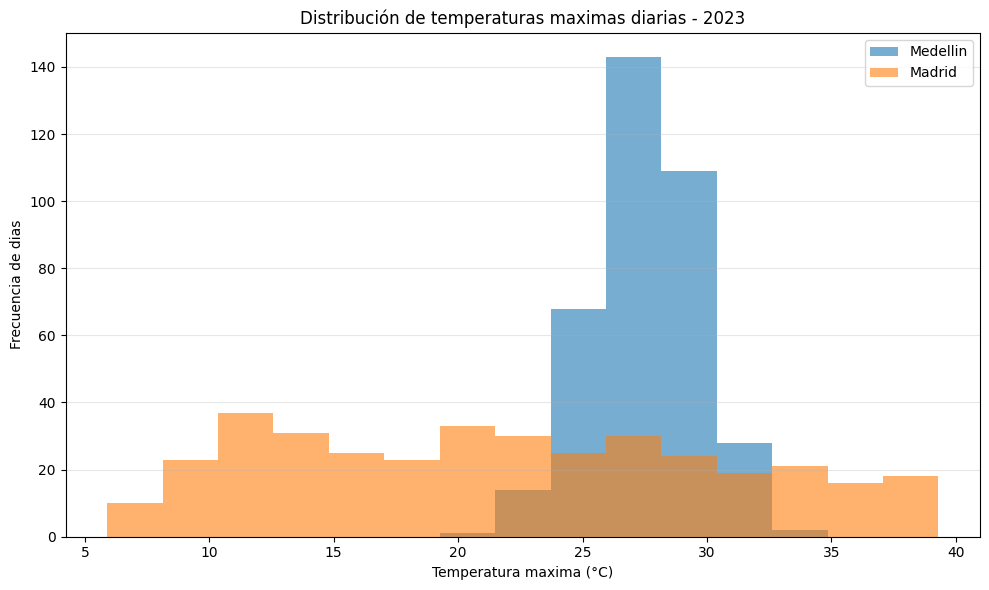

In [ ]:
# DISTRIBUCIÓN DE TEMPERATURAS MAXIMAS

limite_inferior = min(np.min(temp_med), np.min(temp_mad))
limite_superior = max(np.max(temp_med), np.max(temp_mad))

bins = np.linspace(limite_inferior, limite_superior, 16)

plt.figure(figsize=(10, 6))
plt.hist( temp_med, bins=bins, alpha=0.6, label="Medellin" )
plt.hist( temp_mad, bins=bins, alpha=0.6, label="Madrid" )

plt.title("Distribución de temperaturas maximas diarias - 2023")
plt.xlabel("Temperatura maxima (°C)")
plt.ylabel("Frecuencia de dias")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

aca podemos observar como se distribuyen las temperaturas maximas diarias durante el año en ambas ciudades.
Medellin, las temperaturas se concentran en un rango reducido, lo que coincide con su desviación estándar de 2,10 °C.
En Madrid, las temperaturas presentan una distribucion mas amplia, con valores desde 5,9 °C hasta 39,3 °C y una desviación estándar de 8,80 °C.
Esta diferencia nos permitio identificar una mayor variabilidad termica en Madrid, mientras que Medellin presenta temperaturas máximas diarias más concentradas alrededor de su promedio.

#conclusiones

1 El analisis permitio comparar el comportamiento climatico de Medellin y Madrid durante el año 2023 mediante herramientas de Python como Pandas, NumPy y Matplotlib.

2 Se identifico que Medellin presento una temperatura maxima promedio superior a la de Madrid, con 27,53 °C frente a 21,89 °C. Sin embargo, Madrid registro una mayor variación térmica durante el año.

3 En cuanto a la precipitación, Medellín registro una acumulación de 2.782 mm, mientras que Madrid presentó 437,2 mm. Esto evidencia una diferencia importante en la cantidad de lluvia registrada durante el periodo.

4 Las operaciones realizadas con NumPy permitieron trabajar con arreglos, aplicar máscaras booleanas, utilizar broadcasting y calcular estadísticas descriptivas para ambas ciudades.

5 Las gráficas elaboradas con Matplotlib facilitaron la identificacion de patrones y diferencias en la temperatura y la precipitación mensual.

6 Finalmente, la actividad permitió comprender la importancia de la limpieza, organizacion, procesamiento y visualización de los datos para obtener información útil y respaldar conclusiones mediante resultados numéricos.